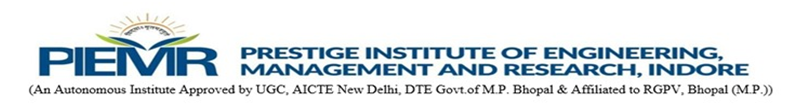


# Step 1: Data and Network Architecture

## Objective

Build the foundation for a neural network that recognizes handwritten digits from 0 to 9.

We will implement the neural network mathematics ourselves using NumPy. We will not use TensorFlow, PyTorch, or scikit-learn to build or train the model.

## Dataset

We use the MNIST handwritten-digit dataset.

- Training images: 60,000
- Test images: 10,000
- Image dimensions: 28 × 28 pixels
- Number of classes: 10 (digits 0–9)

## Libraries

- NumPy: array operations and neural-network mathematics
- Matplotlib: displaying images and diagrams
- TensorFlow/Keras: loading the MNIST dataset only

## Roadmap

1. Load and inspect the data.
2. Preprocess the images.
3. Define the neural-network architecture.
4. Calculate the number of trainable parameters.
5. Implement the forward pass in the next step.



## What Is an Artificial Neuron?

An artificial neuron receives input values, multiplies them by weights, adds a bias, and applies an activation function.

For a neuron with inputs x₁, x₂, ..., xₙ:

z = w₁x₁ + w₂x₂ + ... + wₙxₙ + b

The output is:

a = f(z)

Where:

- x: input values
- w: weights that are adjusted during learning
- b: bias, an additional learnable parameter
- z: weighted sum plus bias
- f: activation function
- a: neuron output

For example, an input pixel may have a normalized brightness of 0.8. Its contribution depends on the weight assigned to it.

A neural network connects many such neurons in layers. During training, the network adjusts its weights and biases to improve its predictions.



RAW DATA INFORMATION
----------------------------------------
Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)
Data type: uint8
Raw pixel range: 0 to 255


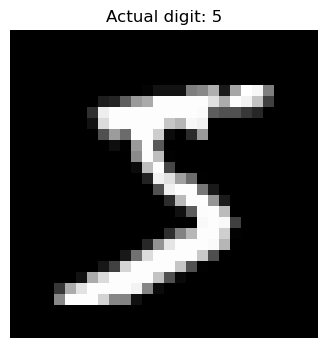

In [1]:

import os
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist

# Reproducibility for our own NumPy operations later
np.random.seed(42)

# Load MNIST
# TensorFlow is used only to load the dataset.
(X_train_raw, y_train), (X_test_raw, y_test) = mnist.load_data()

print("RAW DATA INFORMATION")
print("-" * 40)
print("Training images:", X_train_raw.shape)
print("Training labels:", y_train.shape)
print("Test images:", X_test_raw.shape)
print("Test labels:", y_test.shape)
print("Data type:", X_train_raw.dtype)
print("Raw pixel range:", X_train_raw.min(), "to", X_train_raw.max())

# Display one raw image
plt.figure(figsize=(4, 4))
plt.imshow(X_train_raw[0], cmap="gray")
plt.title(f"Actual digit: {y_train[0]}")
plt.axis("off")
plt.show()




## Preparing the Data

The raw MNIST images are 28 × 28 pixels, with integer pixel values from 0 to 255.

Our fully connected neural network will accept a vector of 784 inputs for each image.

### Step 1: Flattening

28 × 28 = 784 features

Each image changes from a two-dimensional array into a one-dimensional vector.

### Step 2: Normalization

We divide each pixel value by 255:

normalized_pixel = pixel / 255

This changes the pixel range from [0, 255] to [0, 1].

Normalization helps keep the input values within a consistent numerical range.

### Step 3: Labels

The labels remain integers from 0 to 9. They identify the correct digit for each image.

We preserve the raw images separately so they can still be visualized in their original form.


In [2]:

# Flatten each 28 x 28 image into 784 features.
# Convert the pixels to float32 and normalize to [0, 1].

X_train = (
    X_train_raw.reshape(X_train_raw.shape[0], -1)
    .astype(np.float32) / 255.0
)

X_test = (
    X_test_raw.reshape(X_test_raw.shape[0], -1)
    .astype(np.float32) / 255.0
)

# Validate the processed data
assert X_train.shape == (60000, 784)
assert X_test.shape == (10000, 784)

assert y_train.shape == (60000,)
assert y_test.shape == (10000,)

assert X_train.dtype == np.float32
assert X_test.dtype == np.float32

assert np.isfinite(X_train).all()
assert np.isfinite(X_test).all()

assert X_train.min() >= 0.0
assert X_train.max() <= 1.0
assert X_test.min() >= 0.0
assert X_test.max() <= 1.0

assert y_train.min() == 0 and y_train.max() == 9
assert y_test.min() == 0 and y_test.max() == 9

print("PREPROCESSING VALIDATION")
print("-" * 40)
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("Training data type:", X_train.dtype)
print("Test data type:", X_test.dtype)
print("Training pixel range:",
      float(X_train.min()), "to", float(X_train.max()))
print("Test pixel range:",
      float(X_test.min()), "to", float(X_test.max()))
print("Training label range:",
      int(y_train.min()), "to", int(y_train.max()))
print("All validation checks passed.")



PREPROCESSING VALIDATION
----------------------------------------
X_train shape: (60000, 784)
X_test shape: (10000, 784)
Training data type: float32
Test data type: float32
Training pixel range: 0.0 to 1.0
Test pixel range: 0.0 to 1.0
Training label range: 0 to 9
All validation checks passed.


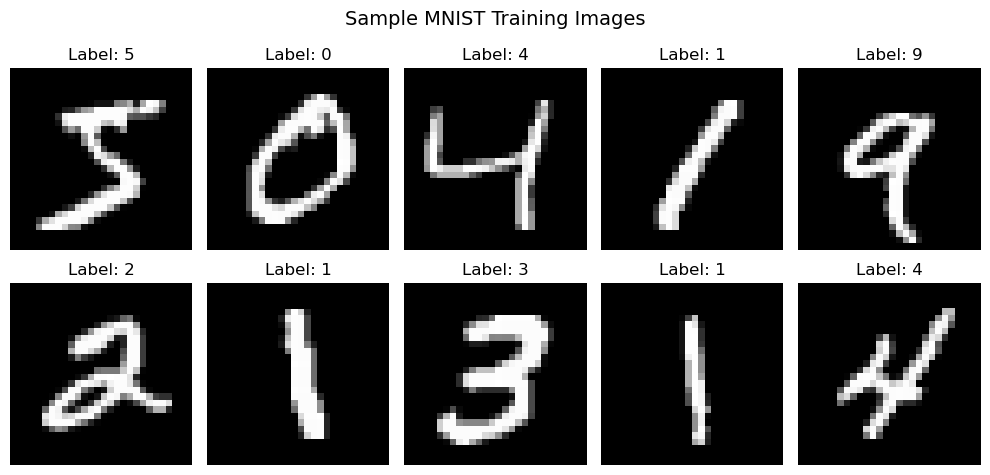

In [3]:

# Create an assets folder for saved figures
os.makedirs("assets", exist_ok=True)

fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    # Reshape the 784 features back to a 28 x 28 image for display
    image = X_train[i].reshape(28, 28)

    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Label: {y_train[i]}")
    ax.axis("off")

fig.suptitle("Sample MNIST Training Images", fontsize=14)
plt.tight_layout()

plt.savefig(
    "assets/sample_digits.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()



## Planning the Neural Network Architecture

We will use a Multi-Layer Perceptron (MLP).

An MLP is a feedforward neural network in which neurons in one layer connect to neurons in the next layer.

Our architecture is:

784 → 128 → 10

### Layer 1: Input layer — 784 inputs

Each input represents the normalized brightness of one pixel in the image.

### Layer 2: Hidden layer — 128 neurons

The hidden layer learns combinations of pixel patterns that may help distinguish digits. We will use the ReLU activation function in the hidden layer in Step 2.

ReLU is defined as:

f(z) = max(0, z)

### Layer 3: Output layer — 10 neurons

Each output corresponds to one possible digit: 0, 1, 2, ..., 9.

The output scores will later be converted into class probabilities using softmax.

The sizes of the input and output layers are determined by the dataset and classification task. The hidden-layer size of 128 is a design choice.


In [4]:

# Define network dimensions
INPUT_SIZE = 784
HIDDEN_SIZE = 128
OUTPUT_SIZE = 10

# Verify that the architecture matches the data
assert X_train.ndim == 2
assert X_test.ndim == 2
assert X_train.shape[1] == INPUT_SIZE
assert X_test.shape[1] == INPUT_SIZE

assert OUTPUT_SIZE == len(np.unique(y_train))
assert OUTPUT_SIZE == 10

print("NETWORK ARCHITECTURE")
print("-" * 40)
print(f"Input layer:  {INPUT_SIZE} neurons")
print(f"Hidden layer: {HIDDEN_SIZE} neurons")
print(f"Output layer: {OUTPUT_SIZE} neurons")
print(f"Architecture: {INPUT_SIZE} -> {HIDDEN_SIZE} -> {OUTPUT_SIZE}")
print(f"Training samples: {X_train.shape[0]:,}")
print(f"Test samples: {X_test.shape[0]:,}")


NETWORK ARCHITECTURE
----------------------------------------
Input layer:  784 neurons
Hidden layer: 128 neurons
Output layer: 10 neurons
Architecture: 784 -> 128 -> 10
Training samples: 60,000
Test samples: 10,000


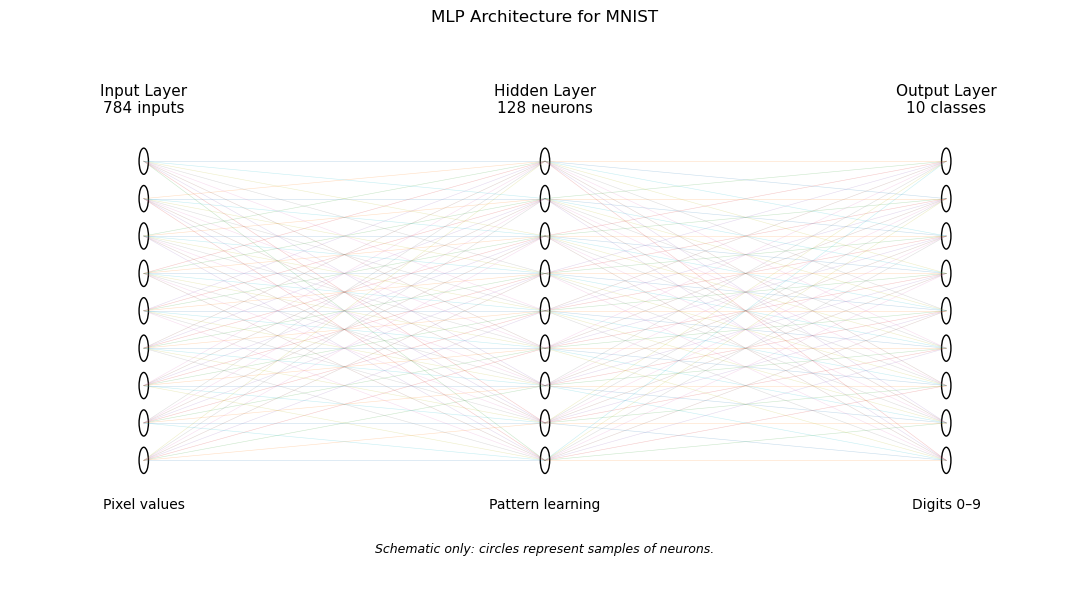

In [5]:

from matplotlib.patches import Circle

fig, ax = plt.subplots(figsize=(11, 6))

# Horizontal positions of the three layers
input_x = 1
hidden_x = 4
output_x = 7

# Draw a representative sample of neurons in each layer
input_y = np.linspace(0.1, 0.9, 9)
hidden_y = np.linspace(0.1, 0.9, 9)
output_y = np.linspace(0.1, 0.9, 9)

# Draw connections from input to hidden layer
for y1 in input_y:
    for y2 in hidden_y:
        ax.plot(
            [input_x, hidden_x],
            [y1, y2],
            linewidth=0.4,
            alpha=0.25
        )

# Draw connections from hidden to output layer
for y1 in hidden_y:
    for y2 in output_y:
        ax.plot(
            [hidden_x, output_x],
            [y1, y2],
            linewidth=0.4,
            alpha=0.25
        )

# Draw neurons
for y in input_y:
    ax.add_patch(Circle((input_x, y), 0.035, fill=False))

for y in hidden_y:
    ax.add_patch(Circle((hidden_x, y), 0.035, fill=False))

for y in output_y:
    ax.add_patch(Circle((output_x, y), 0.035, fill=False))

# Layer labels
ax.text(input_x, 1.02, "Input Layer\n784 inputs",
        ha="center", va="bottom", fontsize=11)

ax.text(hidden_x, 1.02, "Hidden Layer\n128 neurons",
        ha="center", va="bottom", fontsize=11)

ax.text(output_x, 1.02, "Output Layer\n10 classes",
        ha="center", va="bottom", fontsize=11)

ax.text(input_x, 0.0, "Pixel values",
        ha="center", va="top")

ax.text(hidden_x, 0.0, "Pattern learning",
        ha="center", va="top")

ax.text(output_x, 0.0, "Digits 0–9",
        ha="center", va="top")

ax.text(
    4, -0.12,
    "Schematic only: circles represent samples of neurons.",
    ha="center", va="top", fontsize=9, style="italic"
)

ax.set_title("MLP Architecture for MNIST")
ax.set_xlim(0, 8)
ax.set_ylim(-0.22, 1.25)
ax.axis("off")

plt.tight_layout()
plt.show()



## Understanding the Weights and Biases

Every neuron in one layer connects to every neuron in the next layer.

### Input to hidden layer

There are 784 inputs and 128 hidden neurons.

Number of weights:

784 × 128 = 100,352

Each hidden neuron also has one bias:

128 biases

### Hidden to output layer

There are 128 hidden neurons and 10 output neurons.

Number of weights:

128 × 10 = 1,280

Each output neuron also has one bias:

10 biases

Weights determine how strongly inputs influence neurons. Biases allow each neuron to shift its activation independently of the weighted input sum.

These parameters will be initialized in the next steps and adjusted during training.


In [6]:

# Weights between input and hidden layers
n_weights_1 = INPUT_SIZE * HIDDEN_SIZE

# Biases in the hidden layer
n_biases_1 = HIDDEN_SIZE

# Weights between hidden and output layers
n_weights_2 = HIDDEN_SIZE * OUTPUT_SIZE

# Biases in the output layer
n_biases_2 = OUTPUT_SIZE

# Total biases
n_biases = n_biases_1 + n_biases_2

# Total trainable parameters
total_params = n_weights_1 + n_biases_1 + n_weights_2 + n_biases_2

# Verify parameter counts
assert n_weights_1 == 100352
assert n_weights_2 == 1280
assert n_biases_1 == 128
assert n_biases_2 == 10
assert total_params == 101770

print("TRAINABLE PARAMETER COUNT")
print("=" * 45)
print(f"Input -> Hidden weights: {n_weights_1:,}")
print(f"Hidden layer biases:    {n_biases_1:,}")
print(f"Hidden -> Output weights: {n_weights_2:,}")
print(f"Output layer biases:    {n_biases_2:,}")
print("-" * 45)
print(f"Total weights:          {n_weights_1 + n_weights_2:,}")
print(f"Total biases:           {n_biases:,}")
print(f"Total parameters:       {total_params:,}")





TRAINABLE PARAMETER COUNT
Input -> Hidden weights: 100,352
Hidden layer biases:    128
Hidden -> Output weights: 1,280
Output layer biases:    10
---------------------------------------------
Total weights:          101,632
Total biases:           138
Total parameters:       101,770


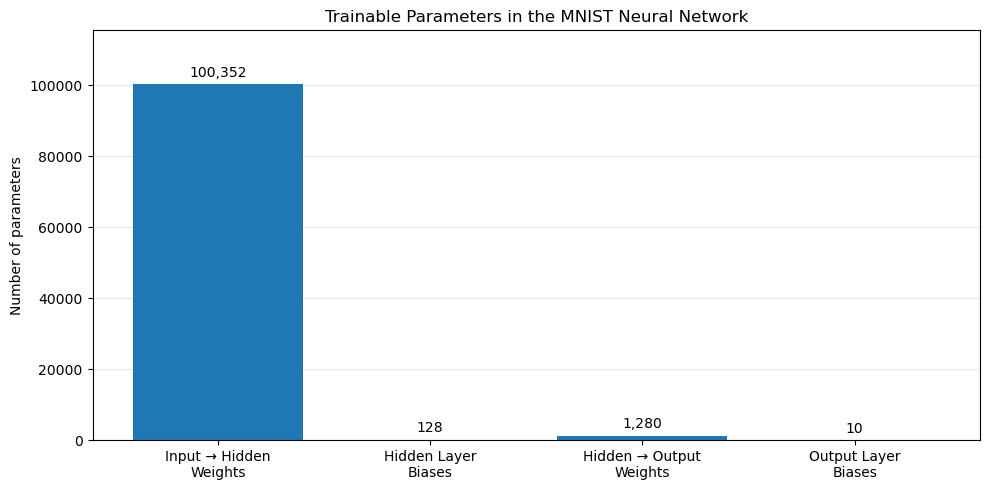

In [7]:

labels = [
    "Input → Hidden\nWeights",
    "Hidden Layer\nBiases",
    "Hidden → Output\nWeights",
    "Output Layer\nBiases"
]

values = [
    n_weights_1,
    n_biases_1,
    n_weights_2,
    n_biases_2
]

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(labels, values)

ax.set_title("Trainable Parameters in the MNIST Neural Network")
ax.set_ylabel("Number of parameters")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

ax.bar_label(
    bars,
    labels=[f"{value:,}" for value in values],
    padding=3
)

ax.set_ylim(0, max(values) * 1.15)

plt.tight_layout()
plt.savefig(
    "assets/parameter_counts.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()



## Step 1 Summary

We have completed the data preparation and architecture design.

- Loaded 60,000 training images and 10,000 test images.
- Flattened each image into 784 features.
- Normalized pixel intensities to [0, 1].
- Defined the network architecture: 784 → 128 → 10.
- Calculated 101,770 trainable parameters.
- Visualized sample digits, the network architecture, and parameter counts.

### Important distinction

We have defined the architecture mathematically, but we have not initialized the network weights or trained the model yet.

### Next step: Implementing the forward pass

In Step 2, we will use NumPy to:

1. Initialize the weight matrices and bias vectors.
2. Calculate the weighted sum for each layer.
3. Apply ReLU to the hidden layer.
4. Apply softmax to the output layer.
5. Generate predicted probabilities for the ten digit classes.

The goal is to understand every mathematical operation before training the network.


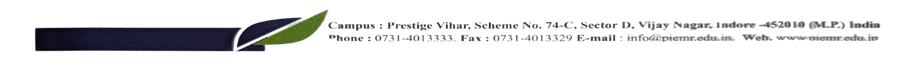